In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("ChargingRecords.csv")

print("Shape:", df.shape)

Shape: (72856, 13)


In [3]:
print("First 5 rows:")
display(df.head())
print("*************************************************************************")
print("\nLast 5 rows:")
display(df.tail())

First 5 rows:


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


*************************************************************************

Last 5 rows:


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
72851,2155,2649,0,public institution,0,2022-01-27,9:54:44,2022-01-27,9:58:57,2022-01-27 9:54,2022-01-27 9:58,4,0.50
72852,2379,2670,0,sightseeing,1,2021-10-31,14:52:11,2021-10-31,15:20:28,2021-10-31 14:52,2021-10-31 15:20,28,16.53
72853,2388,2670,0,sightseeing,1,2021-10-03,13:52:14,2021-10-03,14:32:13,2021-10-03 13:52,2021-10-03 14:32,40,12.20
72854,2388,2671,0,company,1,2021-11-18,11:37:44,2021-11-18,11:45:37,2021-11-18 11:37,2021-11-18 11:45,8,3.80
72855,2388,2671,0,company,1,2021-10-30,17:29:02,2021-10-30,17:36:47,2021-10-30 17:29,2021-10-30 17:36,8,3.67


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72856 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72856 non-null  int64  
 1   ChargerID       72856 non-null  int64  
 2   ChargerCompany  72856 non-null  int64  
 3   Location        72856 non-null  object 
 4   ChargerType     72856 non-null  int64  
 5   StartDay        72856 non-null  object 
 6   StartTime       72856 non-null  object 
 7   EndDay          72856 non-null  object 
 8   EndTime         72856 non-null  object 
 9   StartDatetime   72856 non-null  object 
 10  EndDatetime     72856 non-null  object 
 11  Duration        72856 non-null  int64  
 12  Demand          72856 non-null  float64
dtypes: float64(1), int64(5), object(7)
memory usage: 7.2+ MB


In [5]:
df.describe()

,UserID,ChargerID,ChargerCompany,ChargerType,Duration,Demand
count,72856.000000,72856.000000,72856.000000,72856.00000,72856.000000,72856.000000
mean,338.164667,525.489212,0.627443,0.20524,151.194054,17.444445
std,553.970996,569.544469,0.483489,0.40388,146.430286,13.492728
min,0.000000,1.000000,0.000000,0.00000,-29.000000,0.010000
25%,0.000000,107.000000,0.000000,0.00000,40.000000,7.530000
50%,62.000000,301.000000,1.000000,0.00000,112.000000,14.100000
75%,407.000000,738.000000,1.000000,0.00000,202.000000,23.200000
max,2501.000000,2671.000000,1.000000,1.00000,1573.000000,97.000000


In [6]:
print(df.columns)

Index(['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType',
       'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime',
       'EndDatetime', 'Duration', 'Demand'],
      dtype='object')


In [7]:
print("ChargerCompany:", df["ChargerCompany"].unique())
print("ChargerType:", df["ChargerType"].unique())
print("Location:", df["Location"].unique())

ChargerCompany: [1 0]
ChargerType: [0 1]
Location: ['hotel' 'company' 'apartment' 'resort' 'public area' 'public institution'
 'restaurant' 'accommodation' 'golf' 'sightseeing' 'market' 'camping'
 'public parking lot' 'bus garage']


In [8]:
print("Unique Users:", df["UserID"].nunique())
print("Unique Chargers:", df["ChargerID"].nunique())
print("Unique Companies:", df["ChargerCompany"].nunique())
print("Unique Charger Types:", df["ChargerType"].nunique())
print("Unique Locations:", df["Location"].nunique())

Unique Users: 2337
Unique Chargers: 2119
Unique Companies: 2
Unique Charger Types: 2
Unique Locations: 14


In [9]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
UserID            0
ChargerID         0
ChargerCompany    0
Location          0
ChargerType       0
StartDay          0
StartTime         0
EndDay            0
EndTime           0
StartDatetime     0
EndDatetime       0
Duration          0
Demand            0
dtype: int64


In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 13


## Data Cleaning

In [11]:
before = len(df)

df = df.drop_duplicates().copy()

after = len(df)

print("Rows before:", before)
print("Rows after :", after)
print("Duplicates removed:", before - after)

Rows before: 72856
Rows after : 72843
Duplicates removed: 13


In [12]:
print("Minimum Duration:", df["Duration"].min())
print("Maximum Duration:", df["Duration"].max())

print("\nNon-positive durations:", (df["Duration"] <= 0).sum())

Minimum Duration: -29
Maximum Duration: 1573

Non-positive durations: 735


In [13]:
before = len(df)

df = df[df["Duration"] > 0].copy()

after = len(df)

print("Rows before:", before)
print("Rows after :", after)
print("Invalid rows removed:", before - after)

Rows before: 72843
Rows after : 72108
Invalid rows removed: 735


In [14]:
df["StartDay"] = pd.to_datetime(df["StartDay"], errors="coerce")
df["EndDay"] = pd.to_datetime(df["EndDay"], errors="coerce")
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"], errors="coerce")
df["EndDatetime"] = pd.to_datetime(df["EndDatetime"], errors="coerce")

print(df[["StartDay", "EndDay", "StartDatetime", "EndDatetime"]].dtypes)

StartDay         datetime64[ns]
EndDay           datetime64[ns]
StartDatetime    datetime64[ns]
EndDatetime      datetime64[ns]
dtype: object


In [15]:
print("Invalid StartDay:", df["StartDay"].isna().sum())
print("Invalid EndDay:", df["EndDay"].isna().sum())
print("Invalid StartDatetime:", df["StartDatetime"].isna().sum())
print("Invalid EndDatetime:", df["EndDatetime"].isna().sum())

Invalid StartDay: 0
Invalid EndDay: 0
Invalid StartDatetime: 0
Invalid EndDatetime: 0


In [16]:
start_time_check = pd.to_datetime(
    df["StartTime"],
    format="%H:%M:%S",
    errors="coerce"
)

print("Invalid StartTime:", start_time_check.isna().sum())

Invalid StartTime: 0


Outlier check

In [17]:
Q1 = df["Duration"].quantile(0.25)
Q3 = df["Duration"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Duration"] < lower_bound) |
    (df["Duration"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Potential outliers:", len(outliers))

Q1: 41.0
Q3: 203.0
IQR: 162.0
Lower Bound: -202.0
Upper Bound: 446.0
Potential outliers: 3903


## EDA

Duration Distribution

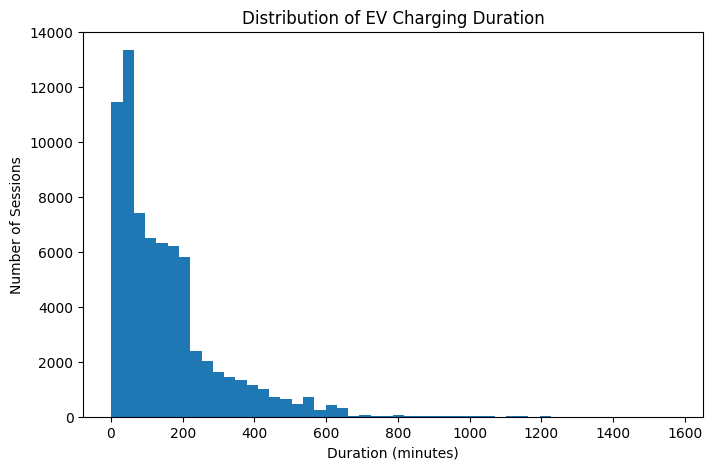

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(df["Duration"], bins=50)

plt.title("Distribution of EV Charging Duration")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Sessions")

plt.show()

Duration Boxplot

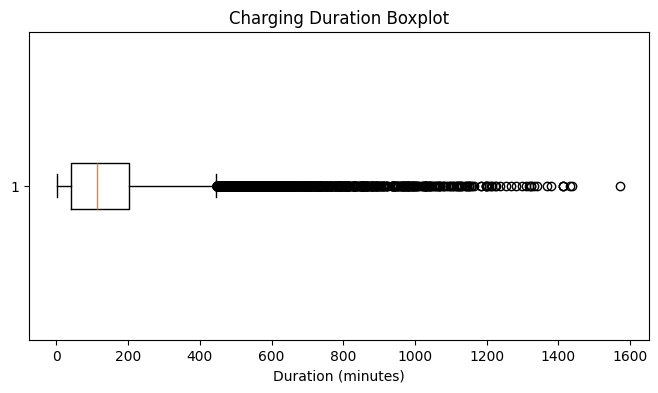

In [19]:
plt.figure(figsize=(8, 4))

plt.boxplot(df["Duration"], vert=False)

plt.title("Charging Duration Boxplot")
plt.xlabel("Duration (minutes)")

plt.show()

Charger Type vs Duration

<Figure size 700x500 with 0 Axes>

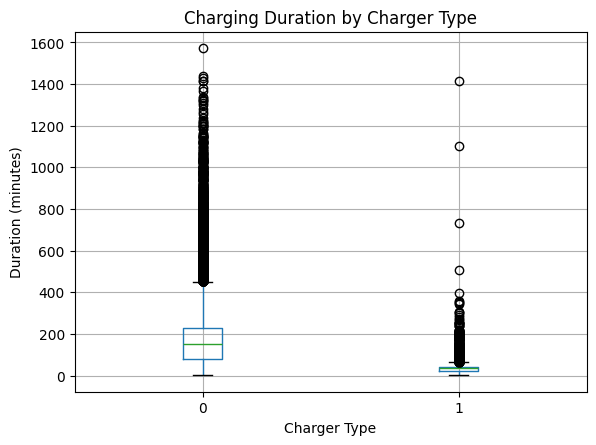

In [20]:
plt.figure(figsize=(7, 5))

df.boxplot(column="Duration", by="ChargerType")

plt.title("Charging Duration by Charger Type")
plt.xlabel("Charger Type")
plt.ylabel("Duration (minutes)")

plt.suptitle("")

plt.show()

Location vs Average Duration

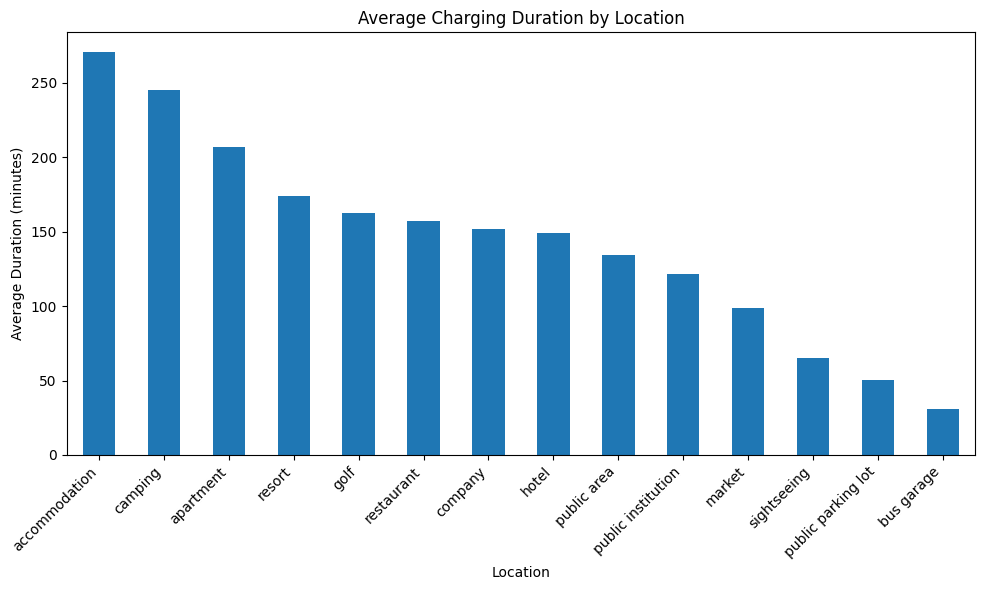

In [21]:
location_duration = (
    df.groupby("Location")["Duration"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

location_duration.plot(kind="bar")

plt.title("Average Charging Duration by Location")
plt.xlabel("Location")
plt.ylabel("Average Duration (minutes)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

Start Hour vs Average Duration

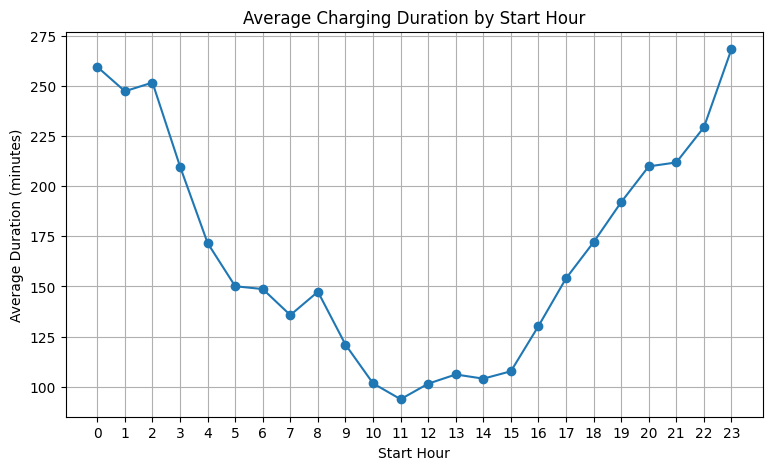

In [22]:
eda_hour = pd.to_datetime(
    df["StartTime"],
    format="%H:%M:%S"
).dt.hour

hour_duration = df.groupby(eda_hour)["Duration"].mean()

plt.figure(figsize=(9, 5))

hour_duration.plot(marker="o")

plt.title("Average Charging Duration by Start Hour")
plt.xlabel("Start Hour")
plt.ylabel("Average Duration (minutes)")
plt.xticks(range(24))

plt.grid(True)
plt.show()

Day of Week vs Average Duration

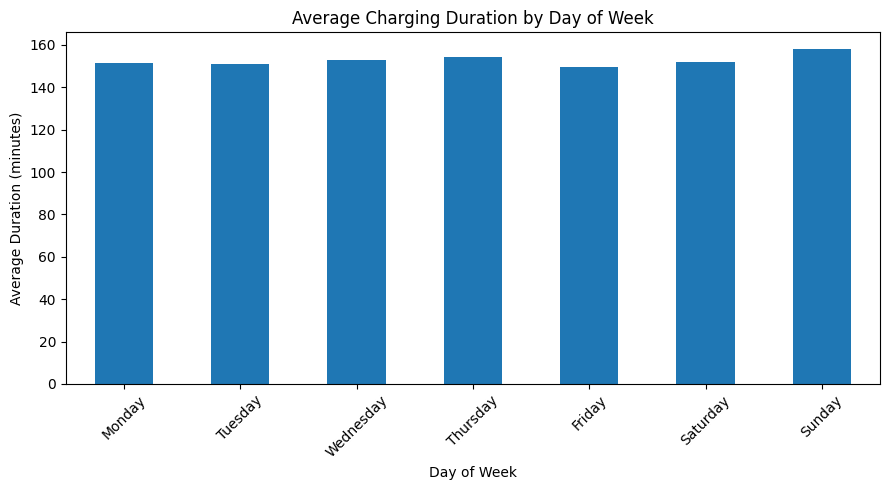

In [23]:
eda_day = df["StartDay"].dt.day_name()

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_duration = (
    df.assign(DayOfWeek=eda_day)
      .groupby("DayOfWeek")["Duration"]
      .mean()
      .reindex(day_order)
)

plt.figure(figsize=(9, 5))

day_duration.plot(kind="bar")

plt.title("Average Charging Duration by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Duration (minutes)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

Simple Correlation Heatmap

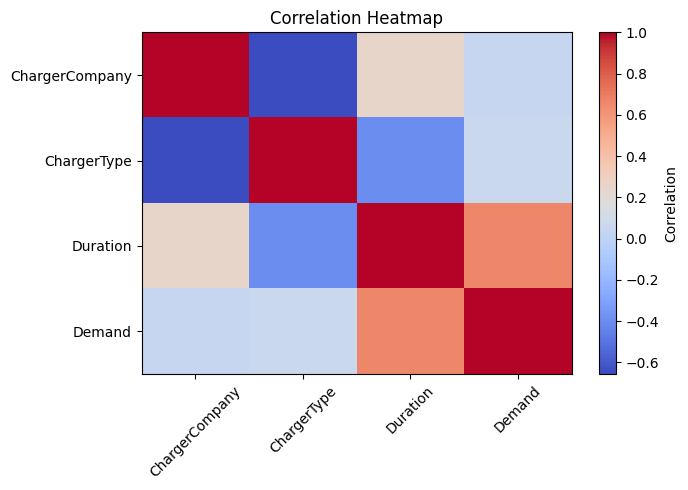

In [24]:
corr_data = df[
    ["ChargerCompany", "ChargerType", "Duration", "Demand"]
].corr()

plt.figure(figsize=(7, 5))

plt.imshow(corr_data, cmap="coolwarm", aspect="auto")

plt.xticks(range(len(corr_data.columns)), corr_data.columns, rotation=45)
plt.yticks(range(len(corr_data.columns)), corr_data.columns)

plt.colorbar(label="Correlation")

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

## Feature Engineering

In [25]:
df["StartHour"] = pd.to_datetime(
    df["StartTime"],
    format="%H:%M:%S"
).dt.hour

In [26]:
df["DayOfWeek"] = df["StartDay"].dt.day_name()

In [27]:
df["Month"] = df["StartDay"].dt.month

In [28]:
df["IsWeekend"] = df["StartDay"].dt.dayofweek >= 5

In [29]:
df[
    [
        "StartDay",
        "StartTime",
        "StartHour",
        "DayOfWeek",
        "Month",
        "IsWeekend"
    ]
].head(10)

,StartDay,StartTime,StartHour,DayOfWeek,Month,IsWeekend
0,2022-09-15,20:54:02,20,Thursday,9,False
1,2022-09-14,20:01:05,20,Wednesday,9,False
2,2022-09-14,18:54:30,18,Wednesday,9,False
3,2022-09-29,18:32:51,18,Thursday,9,False
4,2022-09-25,19:30:15,19,Sunday,9,True
5,2022-09-24,14:51:16,14,Saturday,9,True
6,2022-08-11,18:28:42,18,Thursday,8,False
7,2022-08-10,19:37:54,19,Wednesday,8,False
8,2022-08-09,19:43:27,19,Tuesday,8,False
9,2022-08-07,19:51:01,19,Sunday,8,True


In [30]:
model_df = df[
    [
        "ChargerCompany",
        "Location",
        "ChargerType",
        "StartHour",
        "DayOfWeek",
        "Month",
        "IsWeekend",
        "Duration"
    ]
].copy()

In [31]:
print("Final dataset shape:", model_df.shape)

print("\nColumns:")
print(model_df.columns.tolist())

print("\nMissing values:")
print(model_df.isnull().sum())

print("\nDuplicate rows:")
print(model_df.duplicated().sum())

print("\nMinimum Duration:", model_df["Duration"].min())

Final dataset shape: (72108, 8)

Columns:
['ChargerCompany', 'Location', 'ChargerType', 'StartHour', 'DayOfWeek', 'Month', 'IsWeekend', 'Duration']

Missing values:
ChargerCompany    0
Location          0
ChargerType       0
StartHour         0
DayOfWeek         0
Month             0
IsWeekend         0
Duration          0
dtype: int64

Duplicate rows:
1978

Minimum Duration: 1


In [54]:
model_df.head(10).to_csv("dataset_preview.csv", index=False)

Define X and y

In [32]:
features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "StartHour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

X = model_df[features]
y = model_df["Duration"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (72108, 7)
y shape: (72108,)


## Train/Test Split

In [33]:
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [34]:
features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "StartHour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

X = model_df[features]
y = model_df["Duration"]

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['ChargerCompany', 'Location', 'ChargerType', 'StartHour', 'DayOfWeek', 'Month', 'IsWeekend']
Target: Duration


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

Training data: (57686, 7)
Testing data : (14422, 7)


In [36]:
numeric_features = [
    "StartHour",
    "Month",
    "IsWeekend"
]

categorical_features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "DayOfWeek"
]

In [37]:
def create_preprocessor():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

In [38]:
def train_and_evaluate(model, model_name):

    pipeline = Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

    print(f"{model_name}")
    print(f"MAE  : {mae:.2f}")
    print(f"RMSE : {rmse:.2f}")
    print(f"R²   : {r2:.4f}")
    print("-" * 30)

    return pipeline

In [39]:
results = []
trained_models = {}

Linear Regression

In [40]:
model = LinearRegression()

trained_models["Linear Regression"] = train_and_evaluate(
    model,
    "Linear Regression"
)

Linear Regression
MAE  : 89.52
RMSE : 132.22
R²   : 0.1916
------------------------------


Random Forest

In [41]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

trained_models["Random Forest"] = train_and_evaluate(
    model,
    "Random Forest"
)

Random Forest
MAE  : 89.43
RMSE : 135.74
R²   : 0.1480
------------------------------


Gradient Boosting

In [42]:
model = GradientBoostingRegressor(
    random_state=42
)

trained_models["Gradient Boosting"] = train_and_evaluate(
    model,
    "Gradient Boosting"
)

Gradient Boosting
MAE  : 83.80
RMSE : 125.94
R²   : 0.2666
------------------------------


Compare models

In [43]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values("RMSE")

results_df

,Model,MAE,RMSE,R²
2,Gradient Boosting,83.804321,125.939938,0.266565
0,Linear Regression,89.524633,132.217115,0.191631
1,Random Forest,89.425553,135.735652,0.148034


Save Model -- Joblib

In [44]:
import joblib

In [45]:
best_model_name = "Gradient Boosting"
best_pipeline = trained_models[best_model_name]

joblib.dump(best_pipeline, "ev_charging_time_predictor.pkl")

print("Model saved successfully!")

Model saved successfully!


In [46]:
loaded_pipeline = joblib.load("ev_charging_time_predictor.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [52]:
import sklearn
print(sklearn.__version__)

1.7.2
